# 02 · Criteria layers

Six criteria on the 1 km grid. Slope, crater kernels and areas account for the
east–west pixel shrinking with cos(latitude) in equirectangular (−13 % at 30°).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from marsgis import config as C, grid as G, criteria, overlay, ahp, validation, sensitivity, data, plots
grid = G.reference_grid()
C.FIGURES.mkdir(parents=True, exist_ok=True)
print(grid.shape, grid.crs)

(3556, 21338) IAU_2015:49910


In [2]:
dem, profile = G.read_raster(C.PROCESSED / 'dem_1km.tif')
ti, _ = G.read_raster(C.PROCESSED / 'ti_1km.tif')
cr = pd.read_csv(C.RAW / 'robbins_craters_lat31.csv')

## Slope (degrees, latitude-corrected)

In [3]:
slope = criteria.slope_deg(dem, grid)
G.write_raster(C.PROCESSED / 'slope_1km.tif', slope, grid=grid)
print('slope percentiles 50/95/99:', np.nanpercentile(slope, [50, 95, 99]).round(2))

slope percentiles 50/95/99: [ 0.89  8.19 17.36]


## Roughness

TRI on the 1 km DEM (fast, but mostly measures slope at this scale). For the zoom-in
regions, `criteria.block_std` on the 200 m DEM gives a better roughness — see notebook 04.

In [4]:
rough = criteria.tri(dem)
G.write_raster(C.PROCESSED / 'rough_1km.tif', rough, grid=grid)
print('TRI percentiles 50/95/99 (m):', np.nanpercentile(rough, [50, 95, 99]).round(1))

TRI percentiles 50/95/99 (m): [ 13.8 113.2 234. ]


## Crater density (craters ≥ 1 km per 10,000 km², within 50 km)

In [5]:
crater = criteria.crater_density(cr.lon_e.values, cr.lat.values, grid, C.CRATER_RADIUS_KM)
G.write_raster(C.PROCESSED / 'crater_1km.tif', crater, grid=grid)
print('crater density percentiles 50/95:', np.percentile(crater, [50, 95]).round(1))

crater density percentiles 50/95: [29.3 67.5]


## Latitude

In [6]:
lat = criteria.abs_latitude(grid)
G.write_raster(C.PROCESSED / 'lat_1km.tif', lat, grid=grid)

## Science value (optional)

Needs `data.download_geology()` (810 MB). Noachian/Hesperian units → 1, Amazonian → 0.5,
mixed Amazonian–Hesperian → 0.75. Skipped automatically if the map isn't downloaded.

In [7]:
geo_dir = C.RAW / 'sim3292'
shp = next(geo_dir.rglob('SIM3292_Global_Geology.shp'), None) if geo_dir.exists() else None
if shp:
    import geopandas as gpd
    units = gpd.read_file(shp).to_crs(grid.crs)
    science = criteria.rasterize_polygons(units, units['Unit'].map(criteria.geologic_unit_score), grid)
    G.write_raster(C.PROCESSED / 'science_1km.tif', science, grid=grid)
    print(units['Unit'].map(criteria.geologic_unit_score).value_counts(dropna=False))
else:
    print('geologic map not downloaded; science criterion skipped')

geologic map not downloaded; science criterion skipped


## Quick look

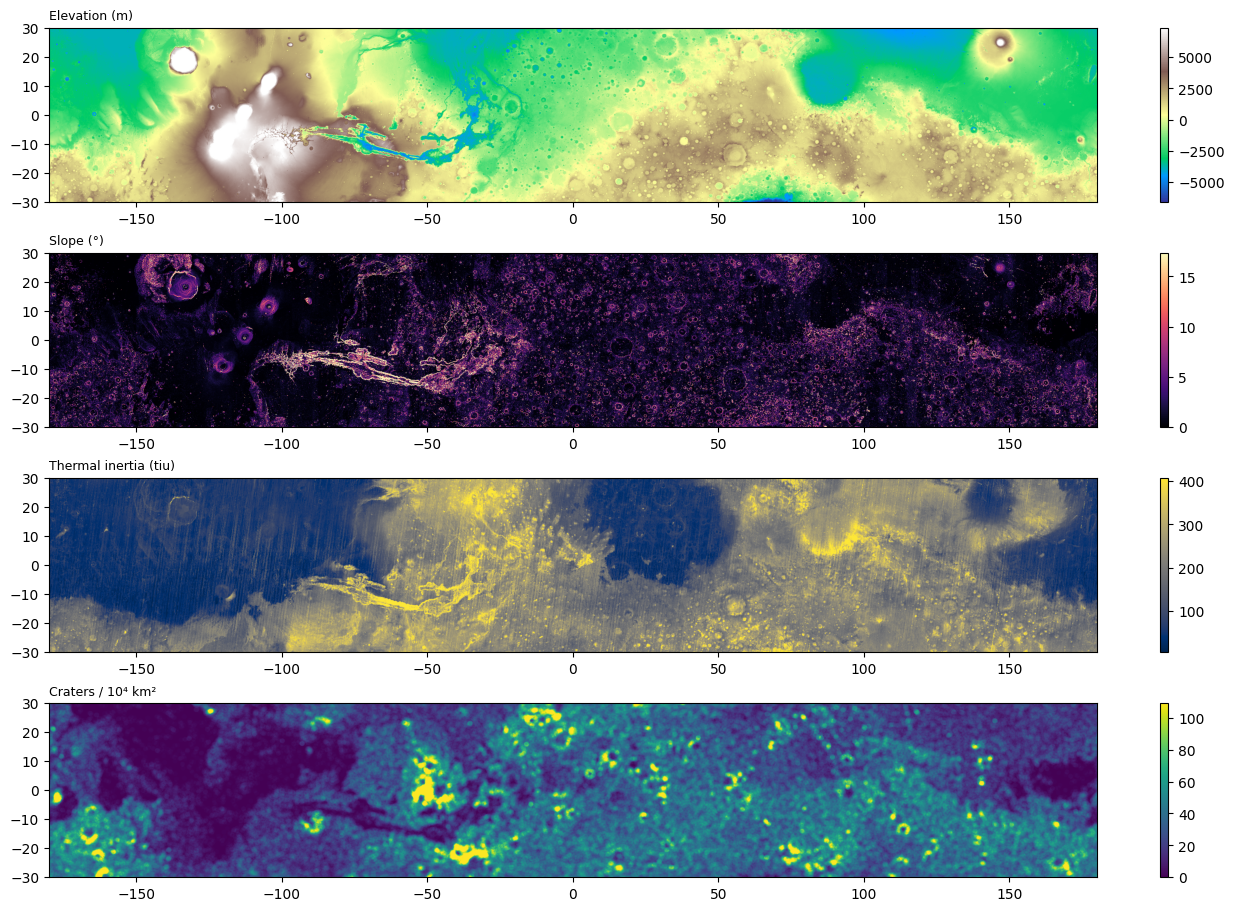

In [8]:
fig, axes = plt.subplots(4, 1, figsize=(14, 9), constrained_layout=True)
for ax, (name, a, cmap) in zip(axes, [('Elevation (m)', dem, 'terrain'), ('Slope (°)', slope, 'magma'),
                                      ('Thermal inertia (tiu)', ti, 'cividis'), ('Craters / 10⁴ km²', crater, 'viridis')]):
    im = ax.imshow(a[::8, ::8], cmap=cmap, vmax=np.nanpercentile(a, 99), extent=[-180, 180, -30, 30])
    ax.set_title(name, fontsize=9, loc='left'); fig.colorbar(im, ax=ax, fraction=0.02)